# Second-pass experiment journal: hypotheses, methods and failures

The user confirmed **public ROC-AUC 0.7654** for `submission_improved.csv`, with displayed rank 1,094 in the supplied screenshot. The public entry is tied to its exact CSV checksum. This notebook documents the next optimization pass, using only the supplied rows and the local venv.

The first-pass audit is now historical. It is not a new untouched test for later choices. All new screening, feature choices and ensemble weights use the original development rows. The complete per-trial record is in `EXPERIMENT_LOG.md`, its JSON/CSV ledger and the source/event files under `improvements/round2`.

First-pass rationales were reconstructed from retained code and are labeled retrospective. Second-pass hypotheses were recorded before their runs; adaptive follow-ups state which earlier result triggered them. Possible explanations are distinguished from proven effects.

In [1]:
from pathlib import Path
import sys,json,numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Code
ROOT=Path.cwd() if (Path.cwd()/'input/train.csv').exists() else Path.cwd()/'Competition'
assert (ROOT/'input/train.csv').exists()
assert Path(sys.prefix).resolve()==(ROOT/'.venv').resolve(), 'Use the project local venv.'
sys.path.insert(0,str(ROOT/'improvements/round2'))
import round2 as r
ART=r.ART
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print('Python:',sys.executable)
print('Known first-pass public score:',r.read(ART/'public_score.json')['public_roc_auc'])

Python: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python
Known first-pass public score: 0.7654


/Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
display(pd.Series(r.read(ART/'environment.json')))
display(pd.Series(r.read(ART/'validation_plan.json')))
public=r.read(ART/'public_score.json');display(pd.Series(public))

python             3.12.15 (main, Oct  6 2026, 23:42:14) [Clang 2...
executable         /Volumes/Projects/GCI World_202609/04. Competi...
prefix             /Volumes/Projects/GCI World_202609/04. Competi...
platform                                  macOS-27.2-arm64-arm-64bit
cpu_count                                                          8
threads_per_fit                                                    4
concurrent_fits                                                    2
packages           {'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy':...
dtype: object

selection_rows                                     original 80% development only
primary_cv_seed                                                         20261110
secondary_cv_seed                                                       20261409
folds                                                                          5
secondary_early_stopping                                                   False
secondary_weight_retuning                                                  False
minimum_primary_oof_gain                                                  0.0002
secondary_acceptance           positive pooled gain and positive gain in at l...
pair_weight_grid               [0.1, 0.25, 0.3333333333333333, 0.5, 0.6666666...
baseline_anchor_retention                                 [0.25, 0.5, 0.75, 0.9]
bootstrap                      600 paired stratified resamples conditional on...
two_seed_final_bagging_gate    Only if averaging both OOF seeds improves on t...
historical_audit            

submission                               output/submission_improved.csv
sha256                71cd8588031deef62dadd8eeddb8e33965cbe42b6e0fc2...
public_roc_auc                                                   0.7654
displayed_rank                                                     1094
displayed_username                                           hasanRocky
source                User-provided screenshot and explicit confirma...
date_recorded                                                2026-11-08
precision             Score and rank as displayed; rank is a snapsho...
dtype: object

## Baseline equivalence and input integrity

The second-pass trainer must reproduce the first-pass compact CatBoost predictions before new results can be compared. Splits, target order, preprocessing and model settings must agree. Feature construction must ignore labels/IDs and produce the same row features alone or in a batch. Hypothetical rate features are checked against their defining equation. The original files and public-scored CSV are preserved.

In [3]:
baseline=r.read(ART/'screen/r2_cat_baseline.json')
display(pd.Series({k:v for k,v in baseline.items() if k not in ['spec','implementation_hash']}))
assert baseline['maximum_prediction_difference']==0
checks=r.read(ART/'verification.json')
display(pd.Series({k:v for k,v in checks.items() if k!='final'}))
print('Final bundle verification is recorded separately after both new notebooks execute.')

name                                                              r2_cat_baseline
seed                                                                     20261108
split                            original inner_fit/inner_valid, development only
status                                                                   complete
auc                                                                      0.748493
average_precision                                                        0.233994
log_loss                                                                 0.248728
iterations                                                                   1670
features                                                                       46
seconds                                                                 85.457976
auc_delta_vs_pass1_cat                                                        0.0
prediction_correlation                                                        1.0
maximum_predicti

preserved_files                         19
all_preserved_hashes_match            True
splits_disjoint                       True
features_ignore_ID_and_TARGET         True
row_batch_invariance                  True
train_test_feature_schema_matches     True
hypothetical_rate_formula_verified    True
observed_scores_strictly_positive     True
unseen_categories_handled             True
numeric_native_missing_preserved      True
dtype: object

Final bundle verification is recorded separately after both new notebooks execute.


## Screening results: keep negative evidence

The screen uses the original 60% fit / 20% validation split. Differences are selection estimates, not final public scores. A lower individual AUC does not rule out ensemble value. The reference for displayed deltas is the first-pass compact CatBoost on these exact rows; comparisons across algorithms change more than one mechanism.

,name,status,kind,features,auc,delta,iterations,seconds,cv_auc
0,r2_cat_term_proxies,complete,cat,finance,0.749952,0.001460,1480,197.400451,0.762254
1,r2_cat_proxies_native,complete,cat,finance,0.749647,0.001155,1724,226.016284,0.761574
2,r2_cat_proxies_rsm075,complete,cat,finance,0.749288,0.000795,1293,154.875642,NaN
3,r2_cat_finance_tuned,complete,cat,finance,0.749273,0.000781,1694,209.017849,NaN
4,r2_cat_finance_native,complete,cat,finance,0.749235,0.000743,1467,206.987224,NaN
5,r2_cat_finance,complete,cat,finance,0.749082,0.000590,1841,177.346512,NaN
6,r2_cat_native_missing,complete,cat,lean,0.748981,0.000489,1660,225.434307,0.760561
7,r2_cat_distances_only,complete,cat,finance,0.748766,0.000273,1953,229.336976,NaN
8,r2_cat_combined,complete,cat,combined,0.748670,0.000177,1576,196.546763,NaN
9,r2_cat_rsm075,complete,cat,lean,0.748607,0.000115,1540,168.286778,NaN


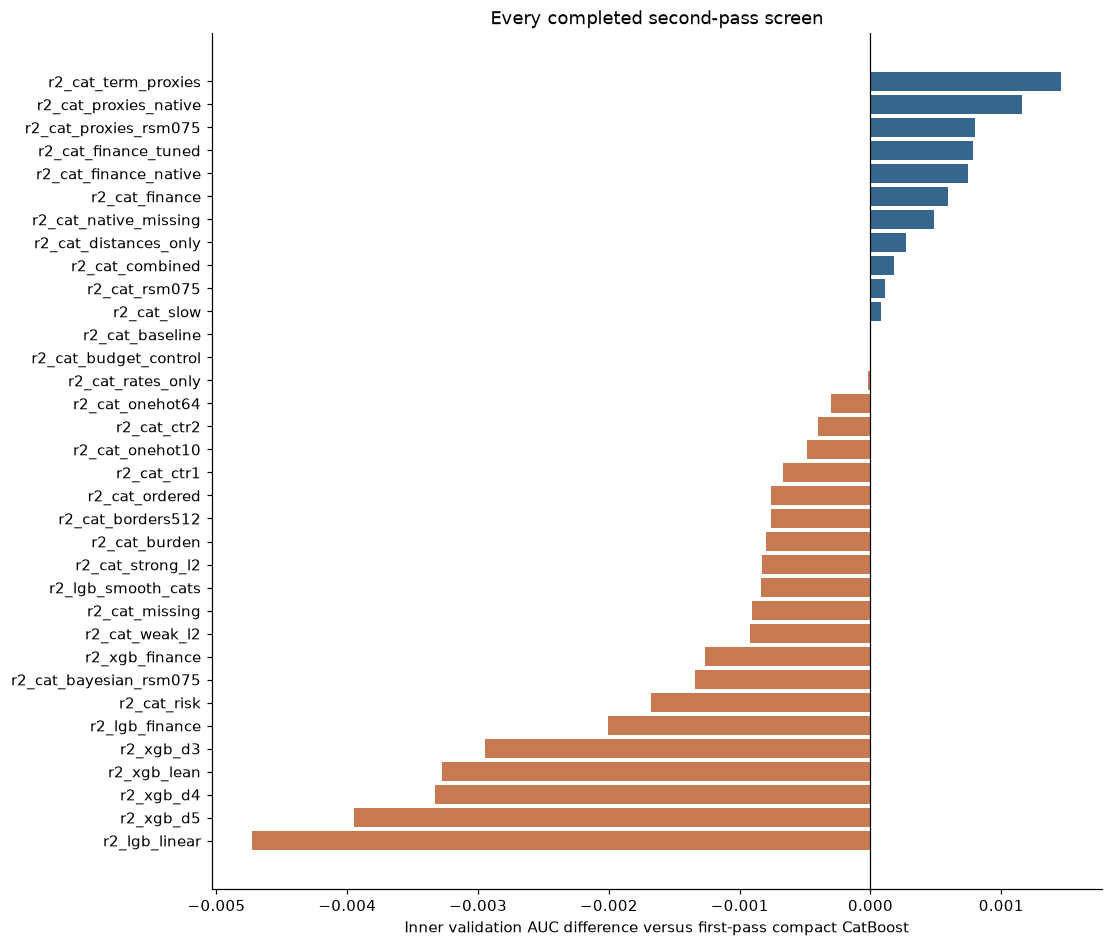

In [4]:
ledger=r.read(ART/'complete_experiment_ledger.json')
current=[a for a in ledger if a['phase']=='pass2']
table=pd.DataFrame([{k:a.get(k) for k in ['name','status','kind','features','auc','delta','iterations','seconds','cv_auc']} for a in current])
display(table.sort_values('auc',ascending=False).reset_index(drop=True))
complete=table[table.status.eq('complete')].sort_values('delta')
fig,ax=plt.subplots(figsize=(10,max(5,.25*len(complete))),layout='constrained')
ax.barh(complete.name,complete.delta,color=np.where(complete.delta>0,'#35678e','#c77951'))
ax.axvline(0,color='black',linewidth=.8)
ax.set(xlabel='Inner validation AUC difference versus first-pass compact CatBoost',title='Every completed second-pass screen')
plt.show()

## Finance ablation: what caused the apparent gain?

The finance block adds payment-burden margins and per-adult amounts, along with nonlinear transforms of credit/annuity. An ablation separates those blocks. A budget control holds features and model parameters fixed while changing the early-stopping patience/cap. Native missing values are tested separately and combined with finance.

The rate features solve a loan-annuity equation for assumed 24/36/60 payment periods. They are **representations of existing input columns**, not recovered contractual rates. The factor 12 in an income margin is an explicit hypothetical frequency transform; the local dictionary does not establish the actual schedule. Extra risk summaries and missingness categories are tested separately rather than assumed useful.

In [5]:
ids=['r2_cat_baseline','r2_cat_budget_control','r2_cat_finance','r2_cat_burden','r2_cat_term_proxies','r2_cat_native_missing','r2_cat_finance_native','r2_cat_finance_tuned']
display(table[table.name.isin(ids)].set_index('name').reindex([n for n in ids if n in set(table.name)]))
import inspect
display(Code(inspect.getsource(r.features),language='python'))

,status,kind,features,auc,delta,iterations,seconds,cv_auc
name,,,,,,,,
r2_cat_baseline,complete,cat,lean,0.748493,0.000000,1670,85.457976,NaN
r2_cat_budget_control,complete,cat,lean,0.748493,0.000000,1670,139.761254,NaN
r2_cat_finance,complete,cat,finance,0.749082,0.000590,1841,177.346512,NaN
r2_cat_burden,complete,cat,finance,0.747691,-0.000801,1695,223.836539,NaN
r2_cat_term_proxies,complete,cat,finance,0.749952,0.001460,1480,197.400451,0.762254
r2_cat_native_missing,complete,cat,lean,0.748981,0.000489,1660,225.434307,0.760561
r2_cat_finance_native,complete,cat,finance,0.749235,0.000743,1467,206.987224,NaN
r2_cat_finance_tuned,complete,cat,finance,0.749273,0.000781,1694,209.017849,NaN


def features(df,mode='lean'):
    if mode in ['lean','engineered','raw']: return old.features(df,mode)
    x=old.features(df,'lean')
    def ratio(a,b): return a/b.replace(0,np.nan)
    if mode in ['risk','combined']:
        ext=x[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']]
        logit=np.log(ext.clip(.0001,.9999)/(1-ext.clip(.0001,.9999)))
        x['EXT_LOGIT_MEAN']=logit.mean(axis=1)
        x['EXT_LOGIT_STD']=logit.std(axis=1)
        x['EXT_GEOMETRIC']=np.exp(np.log(ext.where(ext>0)).mean(axis=1))
        x['EXT_HARMONIC']=ext.notna().sum(axis=1)/(1/ext.where(ext>0)).sum(axis=1,min_count=1)
        weights=np.array([1.,2.,3.])
        x['EXT_WEIGHTED']=(ext*weights).sum(axis=1,min_count=1)/(ext.notna()*weights).sum(axis=1).replace(0,np.nan)
        x['EXT_CONSERVATIVE']=x.EXT_MEAN-x.EXT_STD.fillna(0)
        x['AGE_EXT_INTERACTION']=(-x.DAYS_BIRTH/365.25)*x.EXT_MEAN
        x['TERM_EXT_INTERACTION']=x.CREDIT_TERM*x.EXT_MEAN
    if mode in ['finance','combined']:
        # Hypothetical payment-period transforms, not reconstructed true rates.
        p=ratio(x.AMT_ANNUITY,x.AMT_CREDIT).to_numpy()
        for n in [24,36,60]:
            low=np.zeros(len(x)); high=np.ones(len(x))
            valid=np.isfinite(p)&(p>=1/n)&(p<1.)
            for _ in range(28):
                middle=(low+high)/2
                factor=middle/(-np.expm1(-n*np.log1p(middle)))
                choose=factor<p
                low=np.where(choose,middle,low); high=np.where(choose,high,middle)
            x[f'ASSUMED_PERIOD_RATE_{n}']=np.where(valid,(low+high)/2,np.nan)
        x['TERM_MULTIPLE_6_DISTANCE']=(x.CREDIT_TERM/6-np.rint(x.CREDIT_TERM/6)).abs()
        x['TERM_MULTIPLE_12_DISTANCE']=(x.CREDIT_TERM/12-np.rint(x.CREDIT_TERM/12)).abs()
        x['INCOME_MINUS_12_ANNUITIES']=x.AMT_INCOME_TOTAL-12*x.AMT_ANNUITY
        x['MARGIN_PER_PERSON']=ratio(x.INCOME_MINUS_12_ANNUITIES,x.CNT_FAM_MEMBERS)
        adults=x.CNT_FAM_MEMBERS-x.CNT_CHILDREN
        x['INCOME_PER_ADULT']=ratio(x.AMT_INCOME_TOTAL,adults)
        x['CREDIT_PER_ADULT']=ratio(x.AMT_CREDIT,adults)
        x['GOODS_OVER_INCOME']=ratio(x.AMT_GOODS_PRICE,x.AMT_INCOME_TOTAL)
        x['CREDIT_COST_AMOUNT']=x.AMT_CREDIT-x.AMT_GOODS_PRICE
    if mode in ['missing','combined']:
        cols=['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3','OWN_CAR_AGE','AMT_REQ_CREDIT_BUREAU_YEAR','DAYS_EMPLOYED']
        for c in cols: x[c+'_IS_MISSING']=x[c].isna().astype('int8')
        bits=x[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].isna().astype(int)
        x['EXT_MISSING_PATTERN']=(bits.to_numpy()*[1,2,4]).sum(axis=1).astype(str)
        x['ORGANIZATION_FAMILY']=x.ORGANIZATION_TYPE.str.replace(r':.*','',regex=True)
        x['AGE_BAND_5']=((-x.DAYS_BIRTH/365.25)//5).astype('Int64').astype(str).fillna('__MISSING__')
    return x.replace([np.inf,-np.inf],np.nan)

### Descriptive loan-pattern evidence

These plots use development labels only. Error bars are Wilson binomial intervals for the displayed bins, without adjustment for feature selection or confounding. Associations do not establish that a loan schedule or interest rate causes default. Train/test distribution checks concern features only.

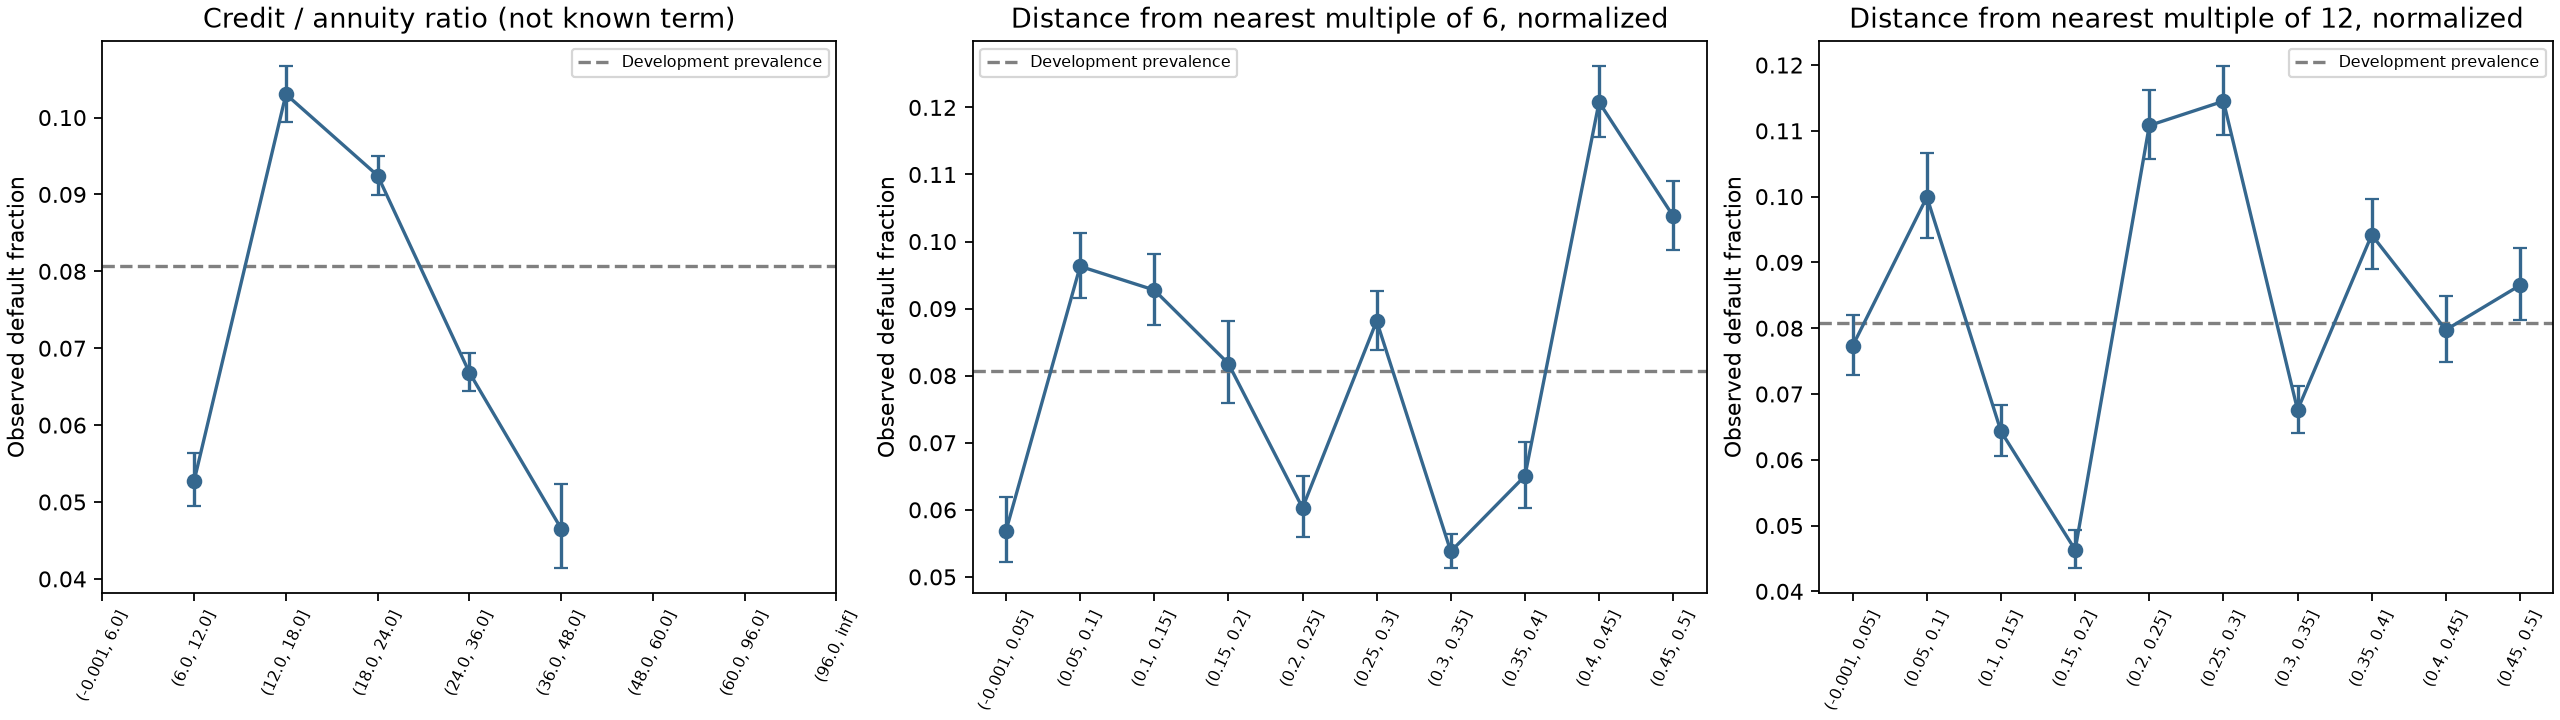

,bin,count,sum,mean,wilson_lower,wilson_upper,feature
0,"(-0.001, 6.0]",NaN,NaN,NaN,NaN,NaN,CREDIT_TERM
1,"(6.0, 12.0]",15854.0,837.0,0.052794,0.049420,0.056385,CREDIT_TERM
2,"(12.0, 18.0]",27293.0,2812.0,0.103030,0.099479,0.106693,CREDIT_TERM
3,"(18.0, 24.0]",48974.0,4528.0,0.092457,0.089924,0.095055,CREDIT_TERM
4,"(24.0, 36.0]",39082.0,2612.0,0.066834,0.064400,0.069353,CREDIT_TERM
5,"(36.0, 48.0]",5758.0,268.0,0.046544,0.041398,0.052294,CREDIT_TERM
6,"(48.0, 60.0]",NaN,NaN,NaN,NaN,NaN,CREDIT_TERM
7,"(60.0, 96.0]",NaN,NaN,NaN,NaN,NaN,CREDIT_TERM
8,"(96.0, inf]",NaN,NaN,NaN,NaN,NaN,CREDIT_TERM
9,"(-0.001, 0.05]",8844.0,503.0,0.056875,0.052237,0.061897,TERM_MULTIPLE_6_DISTANCE


features          [{'feature': 'CREDIT_TERM', 'development_missi...
label_scope                          Original development rows only
interpretation    Descriptive associations after feature explora...
dtype: object

In [6]:
from IPython.display import Image
display(Image(filename=str(ART/'loan_structure_development.png')))
display(pd.read_csv(ART/'loan_structure_development_bins.csv'))
display(pd.Series(r.read(ART/'loan_structure_distribution_check.json')))

## Resolved defaults and implementation details

The saved first-pass model resolves CatBoost bootstrap MVS, maximum categorical-combination complexity 4, 254 numeric borders, one-hot threshold 2 and Plain boosting. A small parameter preflight showed that `bagging_temperature` alone did not switch that configuration to Bayesian bootstrap. The explicit Bayesian follow-up tests the intended mechanism.

Native missing values and a -999 sentinel differ particularly for negative date-offset features: -999 can be a legitimate duration. Numeric quantization can also differ. A score change does not by itself prove which mechanism mattered. Additional categorical crosses and tighter combination limits may reduce or increase variance depending on the representation.

In [7]:
resolved=r.read(ART/'pass1_catboost_resolved_parameters.json')
keys=['bootstrap_type','max_ctr_complexity','border_count','one_hot_max_size','boosting_type','nan_mode','rsm','learning_rate','l2_leaf_reg']
display(pd.Series({k:resolved.get(k) for k in keys}))
display(pd.Series(r.read(ART/'parameter_preflight.json')))
display(Code(inspect.getsource(r.Encoder),language='python'))

bootstrap_type          MVS
max_ctr_complexity        4
border_count            254
one_hot_max_size          2
boosting_type         Plain
nan_mode                Min
rsm                       1
learning_rate         0.045
l2_leaf_reg               8
dtype: object

probe                                                          r2_cat_rsm075
provided_rows                                                            300
iterations                                                                 5
evaluation_score                                                        None
observed_bootstrap_type                                                  MVS
conclusion                 bagging_temperature alone did not switch this ...
impact                     rsm075 remains a column-sampling experiment; a...
dtype: object

class Encoder(old.Encoder):
    def __init__(self,kind='cat',groups=False,missing='sentinel'):
        super().__init__(kind,groups); self.missing=missing
    def fit(self,x):
        super().fit(x)
        self.medians=x.select_dtypes(include='number').median()
        return self
    def transform(self,x):
        if self.kind!='cat': return super().transform(x)
        z=x[self.columns].copy()
        for (c,v),m in self.maps.items():
            a=z[c].map(m).astype(float)
            if v=='frequency': z[c+'_FREQ']=a
            else: z[c+'_'+v+'_REL']=z[v]/a.replace(0,np.nan)
        for c in self.cats: z[c]=z[c].astype(str)
        nums=z.columns.difference(self.cats)
        if self.missing=='sentinel': z[nums]=z[nums].fillna(-999)
        elif self.missing=='median': z[nums]=z[nums].fillna(self.medians)
        z[nums]=z[nums].astype('float32')
        return z.replace([np.inf,-np.inf],np.nan)

## Every trial's hypothesis and interpretation

Full parameter dictionaries, source references, raw evidence paths, fold results and why a trial was retained or rejected are in the ledger. Explanations are conditional: multiple settings often change together, and one validation split can favor a noisy variant. The next notebook checks common folds and a second seed before recommending a new submission.

In [8]:
for a in current:
    display(Markdown(f"### {a['name']}\n**Hypothesis:** {a['hypothesis']}\n\n**Result:** {a['status']}; AUC {a.get('auc')}; delta {a.get('delta')}; CV {a.get('cv_auc')}.\n\n**Interpretation:** {a['interpretation']}\n\n**Evidence:** `{a['artifact']}`"))

### r2_cat_baseline
**Hypothesis:** Reproduce the first-pass compact CatBoost to verify implementation equivalence.

**Result:** complete; AUC 0.7484925822989676; delta 0.0; CV None.

**Interpretation:** Did not improve on the first-pass compact CatBoost on this split; this does not establish universal inferiority.

**Evidence:** `improvements/round2/artifacts/screen/r2_cat_baseline.json`

### r2_cat_risk
**Hypothesis:** Smooth score summaries and score/age/term interactions may help shallow trees model risk.

**Result:** complete; AUC 0.7468125372317196; delta -0.0016800450672480594; CV None.

**Interpretation:** Did not improve on the first-pass compact CatBoost on this split; this does not establish universal inferiority.

**Evidence:** `improvements/round2/artifacts/screen/r2_cat_risk.json`

### r2_cat_finance
**Hypothesis:** Payment burden, per-adult amounts and hypothetical payment-period rates may expose financial structure.

**Result:** complete; AUC 0.7490823704368343; delta 0.000589788137866698; CV None.

**Interpretation:** Improved on the first-pass compact CatBoost on this one split; it still needs CV confirmation.

**Evidence:** `improvements/round2/artifacts/screen/r2_cat_finance.json`

### r2_cat_missing
**Hypothesis:** Joint missing-score patterns and coarse organization groups may expose data-collection segments.

**Result:** complete; AUC 0.7475892741751988; delta -0.0009033081237688201; CV None.

**Interpretation:** Did not improve on the first-pass compact CatBoost on this split; this does not establish universal inferiority.

**Evidence:** `improvements/round2/artifacts/screen/r2_cat_missing.json`

### r2_cat_combined
**Hypothesis:** The three targeted feature families may be complementary; their combination may also add noise.

**Result:** complete; AUC 0.7486699796470049; delta 0.00017739734803723373; CV None.

**Interpretation:** Improved on the first-pass compact CatBoost on this one split; it still needs CV confirmation.

**Evidence:** `improvements/round2/artifacts/screen/r2_cat_combined.json`

### r2_cat_slow
**Hypothesis:** Smaller boosting steps may improve the bias/variance tradeoff.

**Result:** complete; AUC 0.7485719134183243; delta 7.933111935665149e-05; CV None.

**Interpretation:** Improved on the first-pass compact CatBoost on this one split; it still needs CV confirmation.

**Evidence:** `improvements/round2/artifacts/screen/r2_cat_slow.json`

... (24 outputs left out)

### r2_cat_proxies_native
**Hypothesis:** The proxy-only representation improved screening by 0.00146; combine it with the independently promising native missing policy.

**Result:** complete; AUC 0.7496474121388887; delta 0.001154829839921101; CV 0.7615744712299796.

**Interpretation:** Improved on the first-pass compact CatBoost on this one split; it still needs CV confirmation.

**Evidence:** `improvements/round2/artifacts/screen/r2_cat_proxies_native.json`

### r2_cat_rates_only
**Hypothesis:** Separate the hypothetical positive-rate transforms from the term-rounding distances.

**Result:** complete; AUC 0.7484734449020205; delta -1.9137396947144225e-05; CV None.

**Interpretation:** Did not improve on the first-pass compact CatBoost on this split; this does not establish universal inferiority.

**Evidence:** `improvements/round2/artifacts/screen/r2_cat_rates_only.json`

### r2_cat_distances_only
**Hypothesis:** Separate the 6/12-period term-distance transforms from hypothetical rates.

**Result:** complete; AUC 0.7487658160528576; delta 0.00027323375388998983; CV None.

**Interpretation:** Improved on the first-pass compact CatBoost on this one split; it still needs CV confirmation.

**Evidence:** `improvements/round2/artifacts/screen/r2_cat_distances_only.json`

### r2_cat_proxies_rsm075
**Hypothesis:** Test whether the promising proxy block complements column sampling while retaining the resolved MVS bootstrap.

**Result:** complete; AUC 0.7492880773396347; delta 0.0007954950406670047; CV None.

**Interpretation:** Improved on the first-pass compact CatBoost on this one split; it still needs CV confirmation.

**Evidence:** `improvements/round2/artifacts/screen/r2_cat_proxies_rsm075.json`

## Reproduce the screen

Run from `Competition`, with the supplied input folder present:

```sh
.venv/bin/python improvements/round2/round2.py screen
.venv/bin/python improvements/round2/adaptive.py
.venv/bin/python improvements/round2/budget_control.py
.venv/bin/python improvements/round2/proxy_followup.py
.venv/bin/python improvements/round2/secondary_metrics.py
.venv/bin/python improvements/round2/proxy_eda.py
.venv/bin/python improvements/round2/document.py
```

The event journal preserves start/finish times and any failures. Completed trial records contain seeds, stopping counts, runtime, explicit parameters and implementation hashes. Adaptive trials and CV also retain learning curves and resolved parameters where available. The original notebooks and the 0.7654 submission remain unchanged.